# 07 — kNN from Scratch (Part 2, Phase 4)

Implement, document, tune, and assess **exact NumPy kNN** for interest-rate regression and three-class repayment classification. Algorithm code is in `Python/knn.py`; fold-aware experiments are in `Python/knn_experiments.py`. No library kNN estimator or neighbour-search implementation is used.

We reuse Notebook 06's eligible predictors, external chronological split, task-specific month CV, and metrics. **No test outcomes or predictors are read.** These are development results; final test evaluation belongs in Notebook 12.

In [1]:
import sys, json, platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.knn import KNNRegressorScratch, KNNClassifierScratch
from Python.knn_experiments import KNNExperimentConfig, KNNExperimentRunner
from Python.modelling_setup import ModellingDataSetup, ExperimentConfig

OUT = PROJECT_ROOT / 'outputs' / 'knn'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
setup = ModellingDataSetup(PROJECT_ROOT)
protocol = ExperimentConfig()
config = KNNExperimentConfig()
metadata = {'configuration': config.to_dict(), 'split': setup.split_config,
            'protocol': protocol.to_dict(), 'python': platform.python_version(),
            'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'test_policy': 'No test rows read; train-only development models',
            'training_rows': 'Saved positions reference the chronologically sorted training cohort; filenames identify folds',
            'selection': 'CV mean RMSE minimized / CV mean macro F1 maximized; validation scored after selection'}
(OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
seed,42
training_cap,10000
neighbors,"(5, 15, 31)"
weights,"(uniform, distance)"
batch_size,256
blas_threads,2


## 1. Algorithm and computational budget

For query $x$, compute Euclidean distances to fitted observations: $d(x,x_i)=\sqrt{\sum_j(x_j-x_{ij})^2}$. Select the nearest $k$ using NumPy `argpartition`, then sort those indices by distance and fitted row index. The data structure is a contiguous training array plus a bounded batch distance matrix and top-k index table. This exact exhaustive search is appropriate for the roughly 100 encoded dimensions, where a KD-tree may prune poorly.

Regression predicts a uniform or inverse-distance weighted average of neighbour targets. Classification sums neighbour weights by class and normalizes to vote fractions. Equal class votes select the smallest sorted class label. Equal distances at the kth boundary prefer smaller fitted row indices. For distance weighting, exact matches use only zero-distance neighbours; division by zero is avoided. Vote fractions are **not calibrated risk probabilities**.

For $n$ fitted rows, $q$ queries, and $p$ features, exhaustive distance computation costs $O(qnp)$; top-k selection adds approximately $O(qn)$ and sorting $O(qk\log k)$. Working distance memory is $O(bn)$ for batch size $b$, plus $O(np)$ fitted storage and the transformed evaluation matrix. Batched evaluation avoids an entire $q\times n$ distance matrix. Distance computation uses the norm identity and recomputes near-zero candidates directly to reduce cancellation.

**Budget fixed before this run:** at most **10,000 training rows per fold**, within Notebook 06's 50,000 upper cap. Early regression folds use all available rows if fewer. Try $k\in\{5,15,31\}$ and uniform/distance weights: six candidates across five folds. A single max-k neighbour search per fold serves every candidate exactly. Limit BLAS to two threads. Evaluate **all** fold-validation and external validation rows; no evaluation sampling.

Sampling is seeded, without replacement, inside each training partition. Classification uses approximately proportional class allocation with at least one row per available class; it is not rebalanced to equal class sizes. Persist sampled positions and actual class counts. This small training budget is a computational limitation, particularly for rare At risk loans. Fit imputation, scaling, and one-hot encoding **on that fold's sampled training data only**. Unknown categories are ignored by the existing encoder. Numeric scaling and one-hot distances impose a modelling choice: redundant features and many numeric columns can dominate similarity.

## 2. Independently check small examples

These hand-checkable examples verify neighbour order, averaging, vote probabilities, tie rules, and exact duplicates before expensive experiments. Additional independent brute-force and pipeline tests are in `tests/test_knn.py`.

In [2]:
reg_example = KNNRegressorScratch(n_neighbors=2, weights='distance').fit([[0.], [4.]], [10., 30.])
assert np.isclose(reg_example.predict([[1.]])[0], 15.)
clf_example = KNNClassifierScratch(n_neighbors=2, weights='distance').fit([[0.], [4.]], [0, 2])
np.testing.assert_allclose(clf_example.predict_proba([[1.]]), [[0.75, 0.25]])
duplicate_example = KNNRegressorScratch(n_neighbors=3, weights='distance').fit([[1.], [1.], [3.]], [2., 4., 100.])
assert np.isclose(duplicate_example.predict([[1.]])[0], 3.)
tie_example = KNNClassifierScratch(2).fit([[-1.], [1.], [-1.]], [2, 0, 2])
np.testing.assert_array_equal(tie_example.kneighbors([[0.]])[1], [[0, 1]])
assert tie_example.predict([[0.]])[0] == 0
print('Hand-checkable numerical examples passed.')

Hand-checkable numerical examples passed.


## 3. Tune on training CV and evaluate the selected models

Regression retains five full-history expanding-month folds. Classification retains Notebook 06's initial training through February 2014 and five two-month validation blocks in March–December 2014 so all classes are available. Sparse At risk training support remains a major limitation.

Select the lowest mean CV RMSE for regression and highest mean CV macro F1 for classification. Break exact selection ties by smaller k, then alphabetical weight name. Persist the selection before scoring external validation. CV standard deviation describes changing vintages/training sizes, not a confidence interval from independent replicates. No validation-based retuning is performed here.

Fit sample-matched dummy baselines in each partition and also compare with Notebook 06's full-training baselines on the same external validation cohort. Fit/transform time and shared neighbour-search time are reported separately; each candidate shares the same search, so those times must not be summed across candidate rows.

### Expected historical-feature warnings

Some early regression training folds contain entirely missing bureau fields. The existing median imputer drops these fields and applies the same fitted column mask to validation. Warnings are retained for transparency; they do not indicate use of future data. The fold tables record the resulting encoded feature counts. See the final assessment for their implications.

In [3]:
runner = KNNExperimentRunner(setup, OUT, config, protocol)
started = perf_counter()
results = {}
for task in ['regression', 'classification']:
    results[task] = runner.run(task)
    display(Markdown(f'### {task.title()} tuning'))
    display(results[task][1])
    display(results[task][2].dropna(axis=1, how='all'))
elapsed = perf_counter() - started
(OUT / 'execution_summary.json').write_text(json.dumps({'total_experiment_seconds': elapsed}, indent=2))
print(f'Total experiment runtime: {elapsed / 60:.2f} minutes')

/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarnin

regression: CV fold 1/5 complete


/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarnin

regression: CV fold 2/5 complete


/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarnin

regression: CV fold 3/5 complete


... (13 outputs left out)

### Classification tuning

,k,weights,mean,std,count
0,5.0,distance,0.337783,0.004104,5
1,5.0,uniform,0.337325,0.003827,5
2,15.0,distance,0.310837,0.003332,5
3,15.0,uniform,0.310393,0.002990,5
4,31.0,distance,0.301669,0.002003,5
5,31.0,uniform,0.301315,0.001902,5


,task,partition,model,k,weights,n_train_available,n_train,n_evaluation,n_features,fit_transform_seconds,...,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,auc_macro_ovr,auc_micro_ovr,n_train_class_0,n_train_class_1,n_train_class_2
0,classification,validation,knn_scratch,5.0,distance,451671.0,10000,678142,108.0,0.768976,...,0.349702,0.334668,0.763160,0.763160,0.763160,0.565973,0.877381,8291.0,15.0,1694.0
1,classification,validation,dummy_sample_prior,NaN,NaN,NaN,10000,678142,NaN,NaN,...,0.333333,0.290778,0.773577,0.773577,0.773577,0.500000,0.879791,NaN,NaN,NaN


Total experiment runtime: 3.10 minutes


## 4. Cross-validation metrics, minority support, and baseline comparisons

In [4]:
metric_names = ['mae', 'rmse', 'r2', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                'precision_micro', 'recall_micro', 'f1_micro', 'auc_macro_ovr', 'auc_micro_ovr']
summary_rows = []
for task, (cv, tuning, validation_scores) in results.items():
    choice = json.loads((OUT / f'{task}_selection.json').read_text())
    selected = cv[(cv.model == 'knn_scratch') & (cv.k == choice['k']) & (cv.weights == choice['weights'])]
    for metric in metric_names:
        if metric in selected:
            summary_rows.append(dict(task=task, metric=metric, cv_mean=selected[metric].mean(),
                                     cv_std=selected[metric].std(ddof=1), n_valid_folds=int(selected[metric].notna().sum())))
    columns = ['partition', 'n_train_available', 'n_train', 'n_evaluation', 'n_features',
               'fit_transform_seconds', 'shared_neighbor_search_seconds']
    if task == 'classification':
        columns += [f'n_train_class_{label}' for label in [0, 1, 2]]
    display(selected[columns])
cv_summary = pd.DataFrame(summary_rows)
cv_summary.to_csv(OUT / 'selected_cv_summary.csv', index=False)
display(cv_summary)
full_baselines = pd.read_csv(PROJECT_ROOT / 'outputs/modelling_setup/baseline_validation.csv')
validation_tables = []
for task in ['regression', 'classification']:
    table = pd.concat([results[task][2], full_baselines[full_baselines.task == task]], ignore_index=True)
    table = table.dropna(axis=1, how='all')
    table.to_csv(OUT / f'{task}_comparison.csv', index=False)
    validation_tables.append(table)
    display(Markdown(f'### {task.title()}: identical external validation rows'))
    display(table)
assert all(frame.n_evaluation.nunique() == 1 for frame in validation_tables)

,partition,n_train_available,n_train,n_evaluation,n_features,fit_transform_seconds,shared_neighbor_search_seconds
3,cv_1,2412.0,2412,5865,94.0,0.062447,0.209971
11,cv_2,8277.0,8277,16663,95.0,0.046921,1.243985
19,cv_3,24940.0,10000,36118,95.0,0.063147,3.101183
27,cv_4,61058.0,10000,125789,97.0,0.134969,10.293248
35,cv_5,186847.0,10000,279498,102.0,0.277960,21.719398


,partition,n_train_available,n_train,n_evaluation,n_features,fit_transform_seconds,shared_neighbor_search_seconds,n_train_class_0,n_train_class_1,n_train_class_2
1,cv_1,258809.0,10000,34449,109.0,0.077787,2.552511,8439.0,2.0,1559.0
8,cv_2,293258.0,10000,34370,111.0,0.077374,3.035926,8412.0,5.0,1583.0
15,cv_3,327628.0,10000,45416,109.0,0.086659,3.971445,8379.0,7.0,1614.0
22,cv_4,373044.0,10000,46182,108.0,0.088641,3.814272,8344.0,10.0,1646.0
29,cv_5,419226.0,10000,32445,110.0,0.091798,2.781094,8309.0,13.0,1678.0


,task,metric,cv_mean,cv_std,n_valid_folds
0,regression,mae,2.157807,0.423108,5
1,regression,rmse,2.759434,0.553084,5
2,regression,r2,0.461004,0.167535,5
3,classification,accuracy,0.794867,0.007465,5
4,classification,precision_macro,0.382090,0.004806,5
5,classification,recall_macro,0.347765,0.002588,5
6,classification,f1_macro,0.337783,0.004104,5
7,classification,precision_micro,0.794867,0.007465,5
8,classification,recall_micro,0.794867,0.007465,5
9,classification,f1_micro,0.794867,0.007465,5


### Regression: identical external validation rows

,task,partition,model,k,weights,n_train_available,n_train,n_evaluation,n_features,fit_transform_seconds,shared_neighbor_search_seconds,mae,rmse,r2
0,regression,validation,knn_scratch,15.0,distance,466345.0,10000,855502,101.0,0.928681,69.522182,2.978551,3.768190,0.341868
1,regression,validation,dummy_sample_mean,NaN,NaN,NaN,10000,855502,NaN,NaN,NaN,3.822251,4.740755,-0.041699
2,regression,validation,dummy_sample_median,NaN,NaN,NaN,10000,855502,NaN,NaN,NaN,3.788620,4.717786,-0.031630
3,regression,validation,dummy_mean,NaN,NaN,NaN,466345,855502,NaN,NaN,NaN,3.837982,4.752284,-0.046772
4,regression,validation,dummy_median,NaN,NaN,NaN,466345,855502,NaN,NaN,NaN,3.791029,4.719547,-0.032400


### Classification: identical external validation rows

,task,partition,model,k,weights,n_train_available,n_train,n_evaluation,n_features,fit_transform_seconds,...,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,auc_macro_ovr,auc_micro_ovr,n_train_class_0,n_train_class_1,n_train_class_2
0,classification,validation,knn_scratch,5.0,distance,451671.0,10000,678142,108.0,0.768976,...,0.349702,0.334668,0.763160,0.763160,0.763160,0.565973,0.877381,8291.0,15.0,1694.0
1,classification,validation,dummy_sample_prior,NaN,NaN,NaN,10000,678142,NaN,NaN,...,0.333333,0.290778,0.773577,0.773577,0.773577,0.500000,0.879791,NaN,NaN,NaN
2,classification,validation,dummy_most_frequent,NaN,NaN,NaN,451671,678142,NaN,NaN,...,0.333333,0.290778,0.773577,0.773577,0.773577,0.500000,0.830183,NaN,NaN,NaN
3,classification,validation,dummy_prior,NaN,NaN,NaN,451671,678142,NaN,NaN,...,0.333333,0.290778,0.773577,0.773577,0.773577,0.500000,0.879791,NaN,NaN,NaN


## 5. Tuning and regression diagnostics

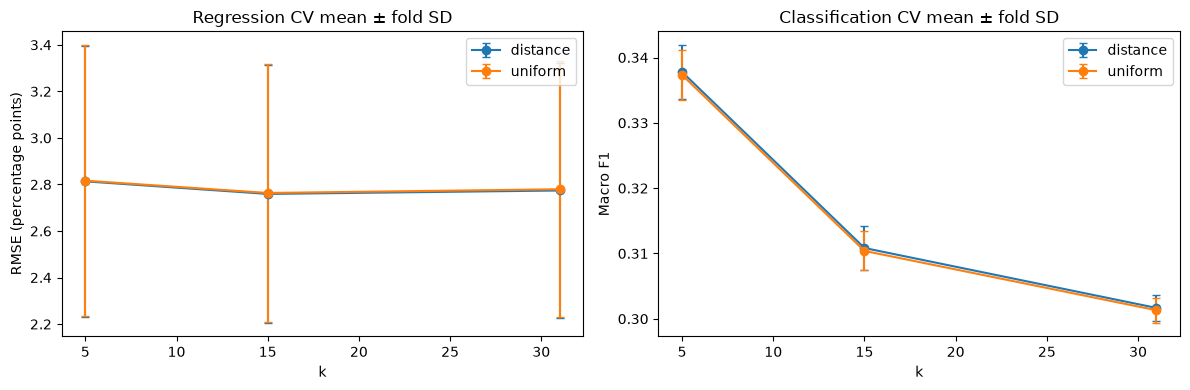

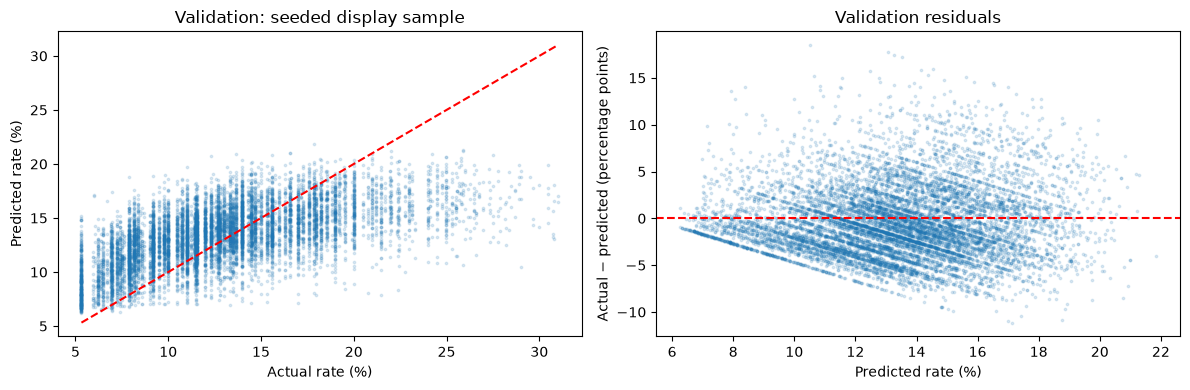

,n,mae,rmse,mean_residual
issue_d,,,,
2015-01,35107.0,2.721692,3.406912,-0.611117
2015-02,23770.0,2.801455,3.464319,-0.856319
2015-03,25400.0,2.835897,3.497905,-0.922823
2015-04,35427.0,2.882353,3.564014,-0.835894
2015-05,31913.0,2.899022,3.585490,-0.838222
2015-06,28485.0,2.854633,3.532721,-0.793627
2015-07,45962.0,2.790062,3.448387,-0.786451
2015-08,35886.0,2.818834,3.470166,-0.942619
2015-09,28641.0,2.822668,3.490719,-0.878433


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, ['regression', 'classification']):
    for weight, frame in results[task][1].groupby('weights'):
        frame = frame.sort_values('k')
        ax.errorbar(frame.k, frame['mean'], yerr=frame['std'], marker='o', capsize=3, label=weight)
    ax.set(title=f'{task.title()} CV mean ± fold SD', xlabel='k',
           ylabel='RMSE (percentage points)' if task == 'regression' else 'Macro F1')
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'tuning.png', dpi=150)
plt.show()
reg = pd.read_parquet(OUT / 'regression_validation_predictions.parquet')
reg['residual'] = reg.int_rate - reg.prediction
sample = reg.sample(n=min(10000, len(reg)), random_state=config.seed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample.int_rate, sample.prediction, s=3, alpha=.15)
limits = [min(sample.int_rate.min(), sample.prediction.min()), max(sample.int_rate.max(), sample.prediction.max())]
axes[0].plot(limits, limits, color='red', linestyle='--')
axes[0].set(xlabel='Actual rate (%)', ylabel='Predicted rate (%)', title='Validation: seeded display sample')
axes[1].scatter(sample.prediction, sample.residual, s=3, alpha=.15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Predicted rate (%)', ylabel='Actual − predicted (percentage points)', title='Validation residuals')
fig.tight_layout()
fig.savefig(FIG / 'regression_diagnostics.png', dpi=150)
plt.show()
monthly = reg.groupby(reg.issue_d.dt.to_period('M')).apply(
    lambda group: pd.Series({'n': len(group), 'mae': group.residual.abs().mean(),
                             'rmse': np.sqrt(np.mean(group.residual ** 2)), 'mean_residual': group.residual.mean()}))
monthly.to_csv(OUT / 'regression_monthly_errors.csv')
display(monthly)

## 6. Classification confusion matrices, per-class metrics, and ROC curves

Report both raw counts and row-normalized recall. ROC curves use local neighbour vote fractions, not hard predictions. AUC measures ranking and can improve even when the default argmax decision misses a rare class. Micro averages are dominated by prevalent classes; macro and per-class results remain essential.

,precision,recall,f1-score,support
Good,0.782698,0.962848,0.863477,524595.00000
At risk,0.000000,0.000000,0.000000,9491.00000
Default,0.378945,0.086258,0.140528,144056.00000
accuracy,0.763160,0.763160,0.763160,0.76316
macro avg,0.387215,0.349702,0.334668,678142.00000
weighted avg,0.685976,0.763160,0.697818,678142.00000


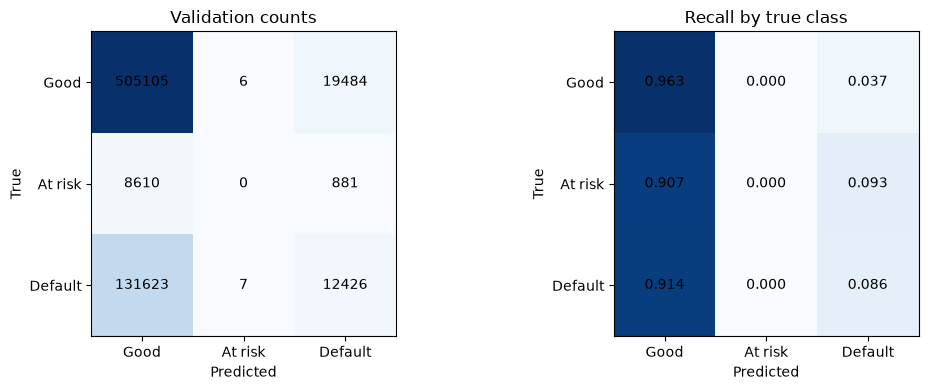

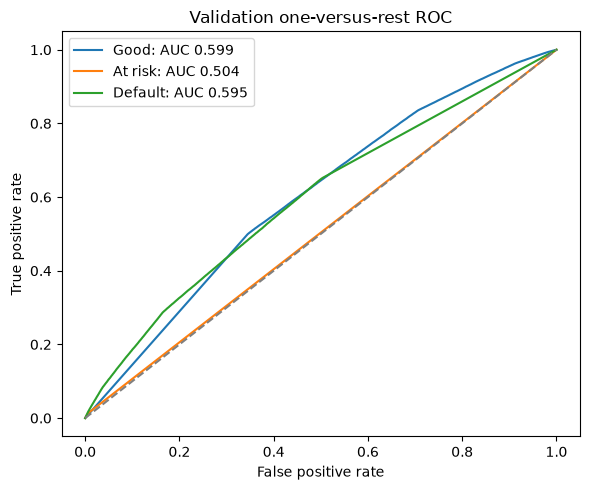

In [6]:
clf = pd.read_parquet(OUT / 'classification_validation_predictions.parquet')
y = clf.target_class.to_numpy()
prediction = clf.prediction.to_numpy()
probability = clf[[f'probability_{label}' for label in [0, 1, 2]]].to_numpy()
assert np.allclose(probability.sum(axis=1), 1)
report = pd.DataFrame(classification_report(y, prediction, labels=[0, 1, 2],
                      target_names=['Good', 'At risk', 'Default'], output_dict=True, zero_division=0)).T
report.to_csv(OUT / 'classification_report.csv')
display(report)
matrix = confusion_matrix(y, prediction, labels=[0, 1, 2])
pd.DataFrame(matrix, index=['Good', 'At risk', 'Default'], columns=['Good', 'At risk', 'Default']).to_csv(OUT / 'classification_confusion_matrix.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in zip(axes, [matrix, matrix / matrix.sum(axis=1, keepdims=True)],
                            ['Validation counts', 'Recall by true class']):
    ax.imshow(values, cmap='Blues')
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, f'{value:.3f}' if values.dtype.kind == 'f' else str(value), ha='center', va='center')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=['Good', 'At risk', 'Default'],
           yticklabels=['Good', 'At risk', 'Default'], xlabel='Predicted', ylabel='True', title=title)
fig.tight_layout()
fig.savefig(FIG / 'classification_confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
binary = label_binarize(y, classes=[0, 1, 2])
for i, name in enumerate(['Good', 'At risk', 'Default']):
    fpr, tpr, _ = roc_curve(binary[:, i], probability[:, i])
    ax.plot(fpr, tpr, label=f'{name}: AUC {auc(fpr, tpr):.3f}')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='Validation one-versus-rest ROC')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'classification_roc.png', dpi=150)
plt.show()

## 7. Interpretation, limitations, and handoff

Models saved here are trained on sampled **training data only** and remain development artifacts. Each bundle contains preprocessing, feature order, model, task, split, and configuration; the experiment runner verifies save/reload predictions. They must not be presented as final test-evaluated deployment models.

Potential limitations include distance concentration in high-dimensional encoded data, correlated engineered features affecting feature weighting, small training samples, rare-class support, snapshot follow-up effects, temporal change, and selection of funded loans. These experiments do not establish causality or fairness. Do not change k, weights, or thresholds in response to held-out test outcomes. Further model comparisons, feature ablations, class-weighting strategies, and group assessments belong in subsequent development notebooks.

In [7]:
r = results['regression'][2].query("model == 'knn_scratch'").iloc[0]
c = results['classification'][2].query("model == 'knn_scratch'").iloc[0]
rb = full_baselines.query("task == 'regression' and model == 'dummy_mean'").iloc[0]
cb = full_baselines.query("task == 'classification' and model == 'dummy_prior'").iloc[0]
reduction = (1 - r.rmse / rb.rmse) * 100
support = results['classification'][0].query("model == 'knn_scratch'").drop_duplicates('partition')
interpretation = f"""# Notebook 07 — observed development results

- Regression selected **k={int(r.k)}, {r.weights} weights** using training CV. Validation MAE **{r.mae:.3f}**, RMSE **{r.rmse:.3f} percentage points**, and R² **{r.r2:.3f}**. RMSE changes by **{reduction:.1f}% lower** relative to Notebook 06's mean baseline ({rb.rmse:.3f}).
- Classification selected **k={int(c.k)}, {c.weights} weights** using training CV. Validation accuracy **{c.accuracy:.2%}**, macro F1 **{c.f1_macro:.3f}** (baseline {cb.f1_macro:.3f}), macro OVR AUC **{c.auc_macro_ovr:.3f}**.
- At risk recall **{report.loc['At risk', 'recall']:.2%}**; Default recall **{report.loc['Default', 'recall']:.2%}**. Minority failures must be considered separately from overall accuracy.
- Classification CV training samples contain only **{int(support.n_train_class_1.min())}–{int(support.n_train_class_1.max())} At risk examples**. Full-training-data and sampled-training-data baselines are both reported; all comparisons use identical evaluation rows.
- Regression mean residual **{reg.residual.mean():.3f} percentage points** (positive means underprediction). Monthly errors and scatterplots show temporal and rate-dependent limitations.
- Total experiment time **{elapsed / 60:.2f} minutes**. Search timings are shared across candidates and must not be added repeatedly.
- Test data remain unread. This demonstrates a working custom algorithm and development performance, not final generalization or deployment readiness.
"""
display(Markdown(interpretation))
(OUT / 'analysis.md').write_text(interpretation + '\n' + '## 8. Assessment of the observed results\n\n**Regression learns a useful signal, with material remaining error.** CV selected 15 neighbours with distance weighting: RMSE **2.759 ± 0.553** across five folds, compared with **3.768** on 2015–2016 validation. Validation RMSE is **20.7% below** the full-training mean baseline and MAE is **2.979 percentage points**. The CV-to-validation gap limits confidence in transferring early-vintage performance to later loans; changing training sizes and feature availability also contribute, so it cannot be attributed to temporal change alone.\n\nThe actual-versus-predicted plot shows predictions compressed toward the middle: low rates are often overpredicted and high rates underpredicted. The average actual-minus-predicted residual is **−0.520 percentage points**, indicating net overprediction. Monthly RMSE ranges from approximately **3.39 to 4.31**; mean residuals turn positive in the second half of 2016. This motivates monitoring error by vintage and rate range. It does not justify tuning against the reserved test set.\n\n**Classification improves one objective but remains unsuitable for risk decisions.** CV selected five distance-weighted neighbours. Validation macro F1 rises from **0.291 to 0.335**, while accuracy falls from **77.36% to 76.32%**. These are different objectives, not contradictory results: the model identifies some defaults at the cost of additional errors on Good loans. Macro AUC is only **0.566**, indicating limited overall class-ranking signal.\n\nThe confusion matrix is decisive: **12,426 of 144,056 defaults** are detected (**8.63% recall**), while **131,623 defaults** are labelled Good. None of the **9,491 At risk loans** is correctly identified. Of the **13** At risk predictions, all are false positives. The final training sample contains only **15 At risk examples**, and CV samples contain **2–13**. Sampling, prevalence, feature representation, and follow-up differences can constrain performance; this experiment does not isolate their individual effects. Sample-matched dummy results confirm that the reported improvements are not simply a change in the constant baseline caused by sampling.\n\n**Preprocessing warnings reflect unavailable historical fields.** Early regression training folds have entirely missing bureau variables. The existing median imputer drops such columns because no training median exists; it applies that same fitted feature mask when transforming evaluation rows. This is fold-safe, and borrowing later values would introduce leakage. Different categorical levels and missing columns explain encoded widths of **94–102** across regression CV folds and **108–111** across classification CV folds. The final development fits use **101** and **108** encoded columns respectively. Consequently early and late folds do not have identical feature information, another limitation of the CV comparison.\n\n**Recommended handoff:** retain these scores as the custom-kNN reference. Proceed with the planned non-ensemble models, using training-only class weights where supported and reporting per-class recall. Evaluate engineered-feature ablations and larger training budgets as explicit development experiments if warranted. Do not present the classifier as an effective risk detector, change the three-class target silently, or claim that development results establish final generalization. Final test data remain reserved.\n')
print('Saved outputs:', OUT.relative_to(PROJECT_ROOT))

# Notebook 07 — observed development results

- Regression selected **k=15, distance weights** using training CV. Validation MAE **2.979**, RMSE **3.768 percentage points**, and R² **0.342**. RMSE changes by **20.7% lower** relative to Notebook 06's mean baseline (4.752).
- Classification selected **k=5, distance weights** using training CV. Validation accuracy **76.32%**, macro F1 **0.335** (baseline 0.291), macro OVR AUC **0.566**.
- At risk recall **0.00%**; Default recall **8.63%**. Minority failures must be considered separately from overall accuracy.
- Classification CV training samples contain only **2–13 At risk examples**. Full-training-data and sampled-training-data baselines are both reported; all comparisons use identical evaluation rows.
- Regression mean residual **-0.520 percentage points** (positive means underprediction). Monthly errors and scatterplots show temporal and rate-dependent limitations.
- Total experiment time **3.10 minutes**. Search timings are shared across candidates and must not be added repeatedly.
- Test data remain unread. This demonstrates a working custom algorithm and development performance, not final generalization or deployment readiness.


Saved outputs: outputs/knn


## 8. Assessment of the observed results

**Regression learns a useful signal, with material remaining error.** CV selected 15 neighbours with distance weighting: RMSE **2.759 ± 0.553** across five folds, compared with **3.768** on 2015–2016 validation. Validation RMSE is **20.7% below** the full-training mean baseline and MAE is **2.979 percentage points**. The CV-to-validation gap limits confidence in transferring early-vintage performance to later loans; changing training sizes and feature availability also contribute, so it cannot be attributed to temporal change alone.

The actual-versus-predicted plot shows predictions compressed toward the middle: low rates are often overpredicted and high rates underpredicted. The average actual-minus-predicted residual is **−0.520 percentage points**, indicating net overprediction. Monthly RMSE ranges from approximately **3.39 to 4.31**; mean residuals turn positive in the second half of 2016. This motivates monitoring error by vintage and rate range. It does not justify tuning against the reserved test set.

**Classification improves one objective but remains unsuitable for risk decisions.** CV selected five distance-weighted neighbours. Validation macro F1 rises from **0.291 to 0.335**, while accuracy falls from **77.36% to 76.32%**. These are different objectives, not contradictory results: the model identifies some defaults at the cost of additional errors on Good loans. Macro AUC is only **0.566**, indicating limited overall class-ranking signal.

The confusion matrix is decisive: **12,426 of 144,056 defaults** are detected (**8.63% recall**), while **131,623 defaults** are labelled Good. None of the **9,491 At risk loans** is correctly identified. Of the **13** At risk predictions, all are false positives. The final training sample contains only **15 At risk examples**, and CV samples contain **2–13**. Sampling, prevalence, feature representation, and follow-up differences can constrain performance; this experiment does not isolate their individual effects. Sample-matched dummy results confirm that the reported improvements are not simply a change in the constant baseline caused by sampling.

**Preprocessing warnings reflect unavailable historical fields.** Early regression training folds have entirely missing bureau variables. The existing median imputer drops such columns because no training median exists; it applies that same fitted feature mask when transforming evaluation rows. This is fold-safe, and borrowing later values would introduce leakage. Different categorical levels and missing columns explain encoded widths of **94–102** across regression CV folds and **108–111** across classification CV folds. The final development fits use **101** and **108** encoded columns respectively. Consequently early and late folds do not have identical feature information, another limitation of the CV comparison.

**Recommended handoff:** retain these scores as the custom-kNN reference. Proceed with the planned non-ensemble models, using training-only class weights where supported and reporting per-class recall. Evaluate engineered-feature ablations and larger training budgets as explicit development experiments if warranted. Do not present the classifier as an effective risk detector, change the three-class target silently, or claim that development results establish final generalization. Final test data remain reserved.
